# $\gamma+\log z$: historical recovery

Exact rational approximants, sampled up to index 500.
$\delta_N=-1-\log|\alpha-p_N/q_N|/\log q_N$ and
$D_N=-\log_{10}|\alpha-p_N/q_N|$, with reduced $p_N/q_N$.
Published results and finite-depth measurements are distinct; source-index exceptions are stated below.

In [ ]:
%pip -q install ramanujantools==0.0.8 sympy==1.14.0 python-flint==0.9.0 matplotlib==3.11.2

## Setup

In [1]:
import sys
import matplotlib.pyplot as plt
import sympy as sp
from flint import arb, ctx
from IPython.display import Markdown, display
from ramanujantools import Matrix
from ramanujantools.cmf.meijer_g import MeijerG

sys.set_int_max_str_digits(0)
DEPTHS = list(range(10, 501, 10))
results, accuracy = {}, {}
a0, a1, b0, b1, b2 = sp.symbols('a0:2 b0:3')
target = lambda z: arb.const_euler() + arb(z).log()


def measure(approximant, target):
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(4 * q.bit_length() + 256):
        error = abs(target() - arb(p) / q)
        assert error > 0 and q > 1
        value = -1 - error.log() / arb(q).log()
        assert value.is_finite() and value.rad() < arb("1e-18")
        return float(value.mid()), float((-error.log() / arb(10).log()).mid())

## 1. Rivoal (2009): third-order construction, $z=2$

[Rivoal (2009), Theorem 1 and recurrence (1.4) at $z=2$](https://rivoal.perso.math.cnrs.fr/articles/eulerconstant.pdf).

**CMF:** $G^{3,2}_{2,3}(2)$, dual, rank 3. **Start:** $(0,0;0,0,0)$. **Direction:** $(0,0;1,1,1)$.
**Readout:** $(PW)_2/(QW)_2$, with $P=(2,1,0)$, $Q=(2,2,1)$, approximating $\gamma+\log 2$.
N is the walk length; one step is one step of (1.4).

In [2]:
cmf = MeijerG(3, 2, 2, 3, 2).dual()
start = {a0: 0, a1: 0, b0: 0, b1: 0, b2: 0}
trajectory = {a0: 0, a1: 0, b0: 1, b1: 1, b2: 1}
P, Q = Matrix([[2, 1, 0]]), Matrix([[2, 2, 1]])
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(P * W)[2] / (Q * W)[2] for W in walks]

measurements = [measure(r, lambda: target(2)) for r in approximants]
deltas = [value[0] for value in measurements]
results['Rivoal (2009), z = 2'] = (DEPTHS, deltas)
accuracy['Rivoal (2009), z = 2'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: -0.887217452446


## 2. Rivoal (2009): third-order construction, $z=3$

[Rivoal (2009), Theorem 1 and recurrence (1.4) at $z=3$](https://rivoal.perso.math.cnrs.fr/articles/eulerconstant.pdf).

**CMF:** $G^{3,2}_{2,3}(3)$, dual, rank 3. **Start:** $(0,0;0,0,0)$. **Direction:** $(0,0;1,1,1)$.
**Readout:** $(PW)_2/(QW)_2$, with $P=(3,1,0)$, $Q=(3,3,1)$, approximating $\gamma+\log 3$.
N is the walk length; one step is one step of (1.4).

In [3]:
cmf = MeijerG(3, 2, 2, 3, 3).dual()
start = {a0: 0, a1: 0, b0: 0, b1: 0, b2: 0}
trajectory = {a0: 0, a1: 0, b0: 1, b1: 1, b2: 1}
P, Q = Matrix([[3, 1, 0]]), Matrix([[3, 3, 1]])
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(P * W)[2] / (Q * W)[2] for W in walks]

measurements = [measure(r, lambda: target(3)) for r in approximants]
deltas = [value[0] for value in measurements]
results['Rivoal (2009), z = 3'] = (DEPTHS, deltas)
accuracy['Rivoal (2009), z = 3'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: -0.875869552264


## 3. Rivoal (2009): third-order construction, $z=4$

[Rivoal (2009), Theorem 1 and recurrence (1.4) at $z=4$](https://rivoal.perso.math.cnrs.fr/articles/eulerconstant.pdf).

**CMF:** $G^{3,2}_{2,3}(4)$, dual, rank 3. **Start:** $(0,0;0,0,0)$. **Direction:** $(0,0;1,1,1)$.
**Readout:** $(PW)_2/(QW)_2$, with $P=(4,1,0)$, $Q=(4,4,1)$, approximating $\gamma+\log 4$.
N is the walk length; one step is one step of (1.4).

In [4]:
cmf = MeijerG(3, 2, 2, 3, 4).dual()
start = {a0: 0, a1: 0, b0: 0, b1: 0, b2: 0}
trajectory = {a0: 0, a1: 0, b0: 1, b1: 1, b2: 1}
P, Q = Matrix([[4, 1, 0]]), Matrix([[4, 4, 1]])
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(P * W)[2] / (Q * W)[2] for W in walks]

measurements = [measure(r, lambda: target(4)) for r in approximants]
deltas = [value[0] for value in measurements]
results['Rivoal (2009), z = 4'] = (DEPTHS, deltas)
accuracy['Rivoal (2009), z = 4'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: -0.862520433223


## Comparison

Only completed runs are shown. N follows each example’s stated index convention.

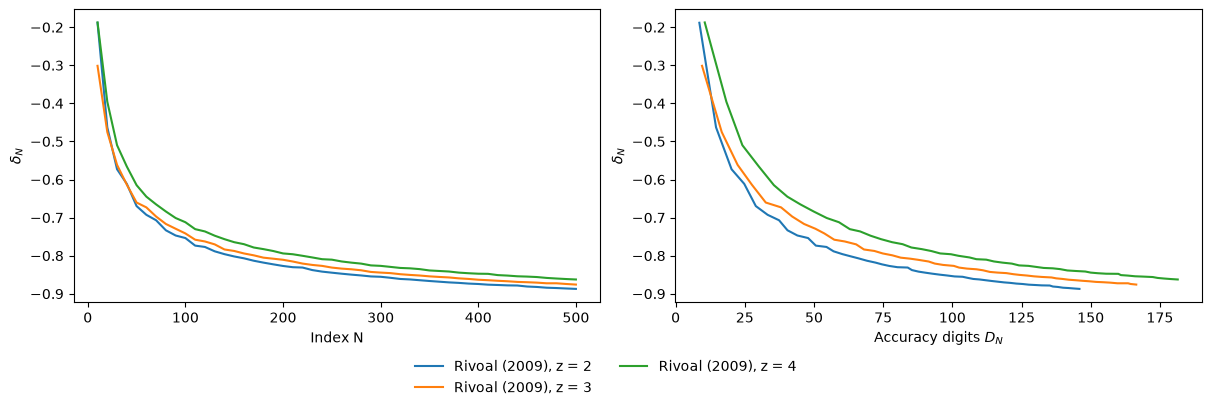

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name, (depths, deltas) in results.items():
    axes[0].plot(depths, deltas, label=name)
    axes[1].plot(accuracy[name], deltas)
axes[0].set(xlabel="Index N", ylabel=r"$\delta_N$")
axes[1].set(xlabel=r"Accuracy digits $D_N$", ylabel=r"$\delta_N$")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=2, frameon=False)
plt.show()

## Historical overview

Only implemented CMF recoveries are listed. The measured column states the actual final index.

In [6]:
bounds = {
    'Rivoal (2009), z = 2': 'Subexponential error estimate; no irrationality-measure bound',
    'Rivoal (2009), z = 3': 'Subexponential error estimate; no irrationality-measure bound',
    'Rivoal (2009), z = 4': 'Subexponential error estimate; no irrationality-measure bound',
}
rows = ["| Construction | Published result | Measured delta |", "|:--|:--|:--|"]
for name, bound in bounds.items():
    if name in results:
        depths, deltas = results[name]
        value = f"{deltas[-1]:.12f} (N = {depths[-1]})"
    else:
        value = "Not computed"
    rows.append(f"| {name} | {bound} | {value} |")
display(Markdown("\n".join(rows)))

| Construction | Published result | Measured delta |
|:--|:--|:--|
| Rivoal (2009), z = 2 | Subexponential error estimate; no irrationality-measure bound | -0.887217452446 (N = 500) |
| Rivoal (2009), z = 3 | Subexponential error estimate; no irrationality-measure bound | -0.875869552264 (N = 500) |
| Rivoal (2009), z = 4 | Subexponential error estimate; no irrationality-measure bound | -0.862520433223 (N = 500) |